In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import ScalarFormatter
%matplotlib inline
import pandas as pd
from planet_cookbook import read_reports as rr
import os
import rebound
import seaborn as sns

sol_to_earth = 332946.078
G = 6.6743* 10**(-11) #N⋅m2/kg2
M_sun = 1.989e+33 #g
AU = 1.496e+13 #cm

In [2]:
from IPython.display import HTML
HTML("<style>div.text_cell_render {font-size: 20px;}</style>")

In [3]:
params = {
   'axes.labelsize': 15,
   'font.size': 15,
   'legend.fontsize': 10,
   'xtick.labelsize': 15,
   'ytick.labelsize': 15,
   'text.usetex': True, #to use TeX in your labels
   'font.family':'serif',
   'axes.titlesize': 15
   }
rcParams.update(params)

#Color-blind friendly pallete
colors = [
    "#0C7BDC",  # Vibrant Blue
    "#E66100",  # Bright Orange
    "#40B0A6",  # Teal/Aqua
    "#8B8D8B",  # Medium Grey
    "#5D3A9B"   # Muted Purple
]

pd.set_option("display.float_format", "{:.3e}".format)


In [4]:
solar_system_df = pd.read_csv('../evolved_planets/solarsystem.csv')
mercury = solar_system_df[solar_system_df['name'] == 'Mercury']
venus = solar_system_df[solar_system_df['name'] == 'Venus']
earth = solar_system_df[solar_system_df['name'] == 'Earth']
mars = solar_system_df[solar_system_df['name'] == 'Mars']

In [6]:
base_path = "/Users/honeyeah/Codes/data/" #folder with all data

sim_set = "cham_bi_tajer/" #name of simulation set, folder with subfolders the name "sim_set_i"
sim_archive_path = base_path + sim_set + "cham_bi_tajer_" #path given to get_runtime_data function
cham_bi_tajer_rdf = rr.get_runtime_data(sim_archive_path, 50, "cham_simarchive_") #rdf is runtime data frame

cut_time = 299.9e6

n_runs_cham_bi_tajer = 50

maxtimes_cham_bi_tajer = np.array([
    cham_bi_tajer_rdf[cham_bi_tajer_rdf['simulation_id'] == i + 1]['time'].max()
    for i in range(n_runs_cham_bi_tajer)
])

keep_cham_bi_tajer = np.where(maxtimes_cham_bi_tajer > 299.9e6)[0]

print("number of finished runs\n")
print(f"cham_bi_tajer: {len(keep_cham_bi_tajer)}")

number of finished runs

cham_bi_tajer: 9


In [8]:
#FOR UEDA V3

cham_bi_tajer_ppdf_list = rr.get_particle_params_at_time(
    f"/Users/honeyeah/Codes/data/cham_bi_tajer/cham_bi_tajer_", keep_cham_bi_tajer, "cham_simarchive_", cut_time
)

cham_bi_tajer_pldf_list = []
for j, i in enumerate(keep_cham_bi_tajer):
    if i == 26:
        continue
    df = rr.read_dbct_output(
        f"/Users/honeyeah/Codes/data/cham_bi_tajer/cham_bi_tajer_{i+1}/uniform_33.txt",
        0.3, "none", "none"
    )

    df_len = len(df)
    param_len = len(cham_bi_tajer_ppdf_list[j])

    min_len = min(df_len, param_len)

    if min_len == 0:
        print(f"Skipping index {i}: empty df or param list.")
        continue

    # Trim both to same length
    df = df.iloc[:min_len].copy()
    semi_values = cham_bi_tajer_ppdf_list[j]['semi'][:min_len]
    df['semi'] = semi_values.values  # if semi_values is a Series
    df['sim_id'] = i + 1

    cham_bi_tajer_pldf_list.append(df)


/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:103: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed. Binary file was saved with REBOUND Version 4.4.7. You are currently using REBOUND Version 4.4.8.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: You have to reset function pointers after creating a reb_simulation struct with a binary file.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:103: Run

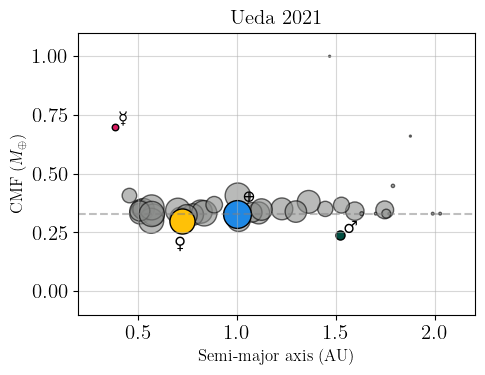

time = 3.00e+08 yrs


In [9]:
cham_bi_tajer_pldf = pd.concat(cham_bi_tajer_pldf_list)

fig, ax = plt.subplots(figsize=(5, 4))

dot_scale = 400
color = colors[3]

ax.grid(True, alpha=0.5)
ax.plot([0.2, 2.2], [0.33, 0.33], linestyle='dashed', color='grey', alpha=0.5)

# Scatter for Ueda 2021 data
ax.scatter(
    cham_bi_tajer_pldf['semi'], cham_bi_tajer_pldf['cmf'],
    alpha=0.6, color=color, edgecolors='black', linewidths=1,
    s=cham_bi_tajer_pldf['mass'] * sol_to_earth * dot_scale
)

# Add Mercury
ax.scatter(0.387, 0.7, color='#D81B60', edgecolors='black', linewidths=1, s=0.055 * dot_scale, label='Mercury')
ax.annotate('☿', [0.4, 0.71], fontsize=12, usetex=False)

# Add Venus
ax.scatter(0.723, 0.3, color='#FFC107', edgecolors='black', linewidths=1, s=0.815 * dot_scale, label='Venus')
ax.annotate('♀', [0.68, 0.18], fontsize=12, usetex=False)

# Add Earth
ax.scatter(1, 0.33, color='#1E88E5', edgecolors='black', linewidths=1, s=dot_scale, label='Earth')
ax.annotate('⊕', [1.02, 0.38], fontsize=12, usetex=False)

# Add Mars
ax.scatter(1.52, 0.24, color='#004D40', edgecolors='black', linewidths=1, s=0.107 * dot_scale, label='Mars')
ax.annotate('♂', [1.53, 0.25], fontsize=12, usetex=False)

# Axis limits & labels
ax.set_xlim(0.2, 2.2)
ax.set_ylim(-0.1, 1.1)
ax.set_xlabel('Semi-major axis (AU)', fontsize=12)
ax.set_ylabel(r'CMF ($M_\oplus$)', fontsize=12)
ax.set_title("Ueda 2021")

plt.tight_layout()
plt.show()

print(f"time = {cut_time:.2e} yrs")


In [10]:
len(cham_bi_tajer_pldf['sim_id'].unique())

9

We start with plotting all Ueda simulations and pick a few intresting ones. 

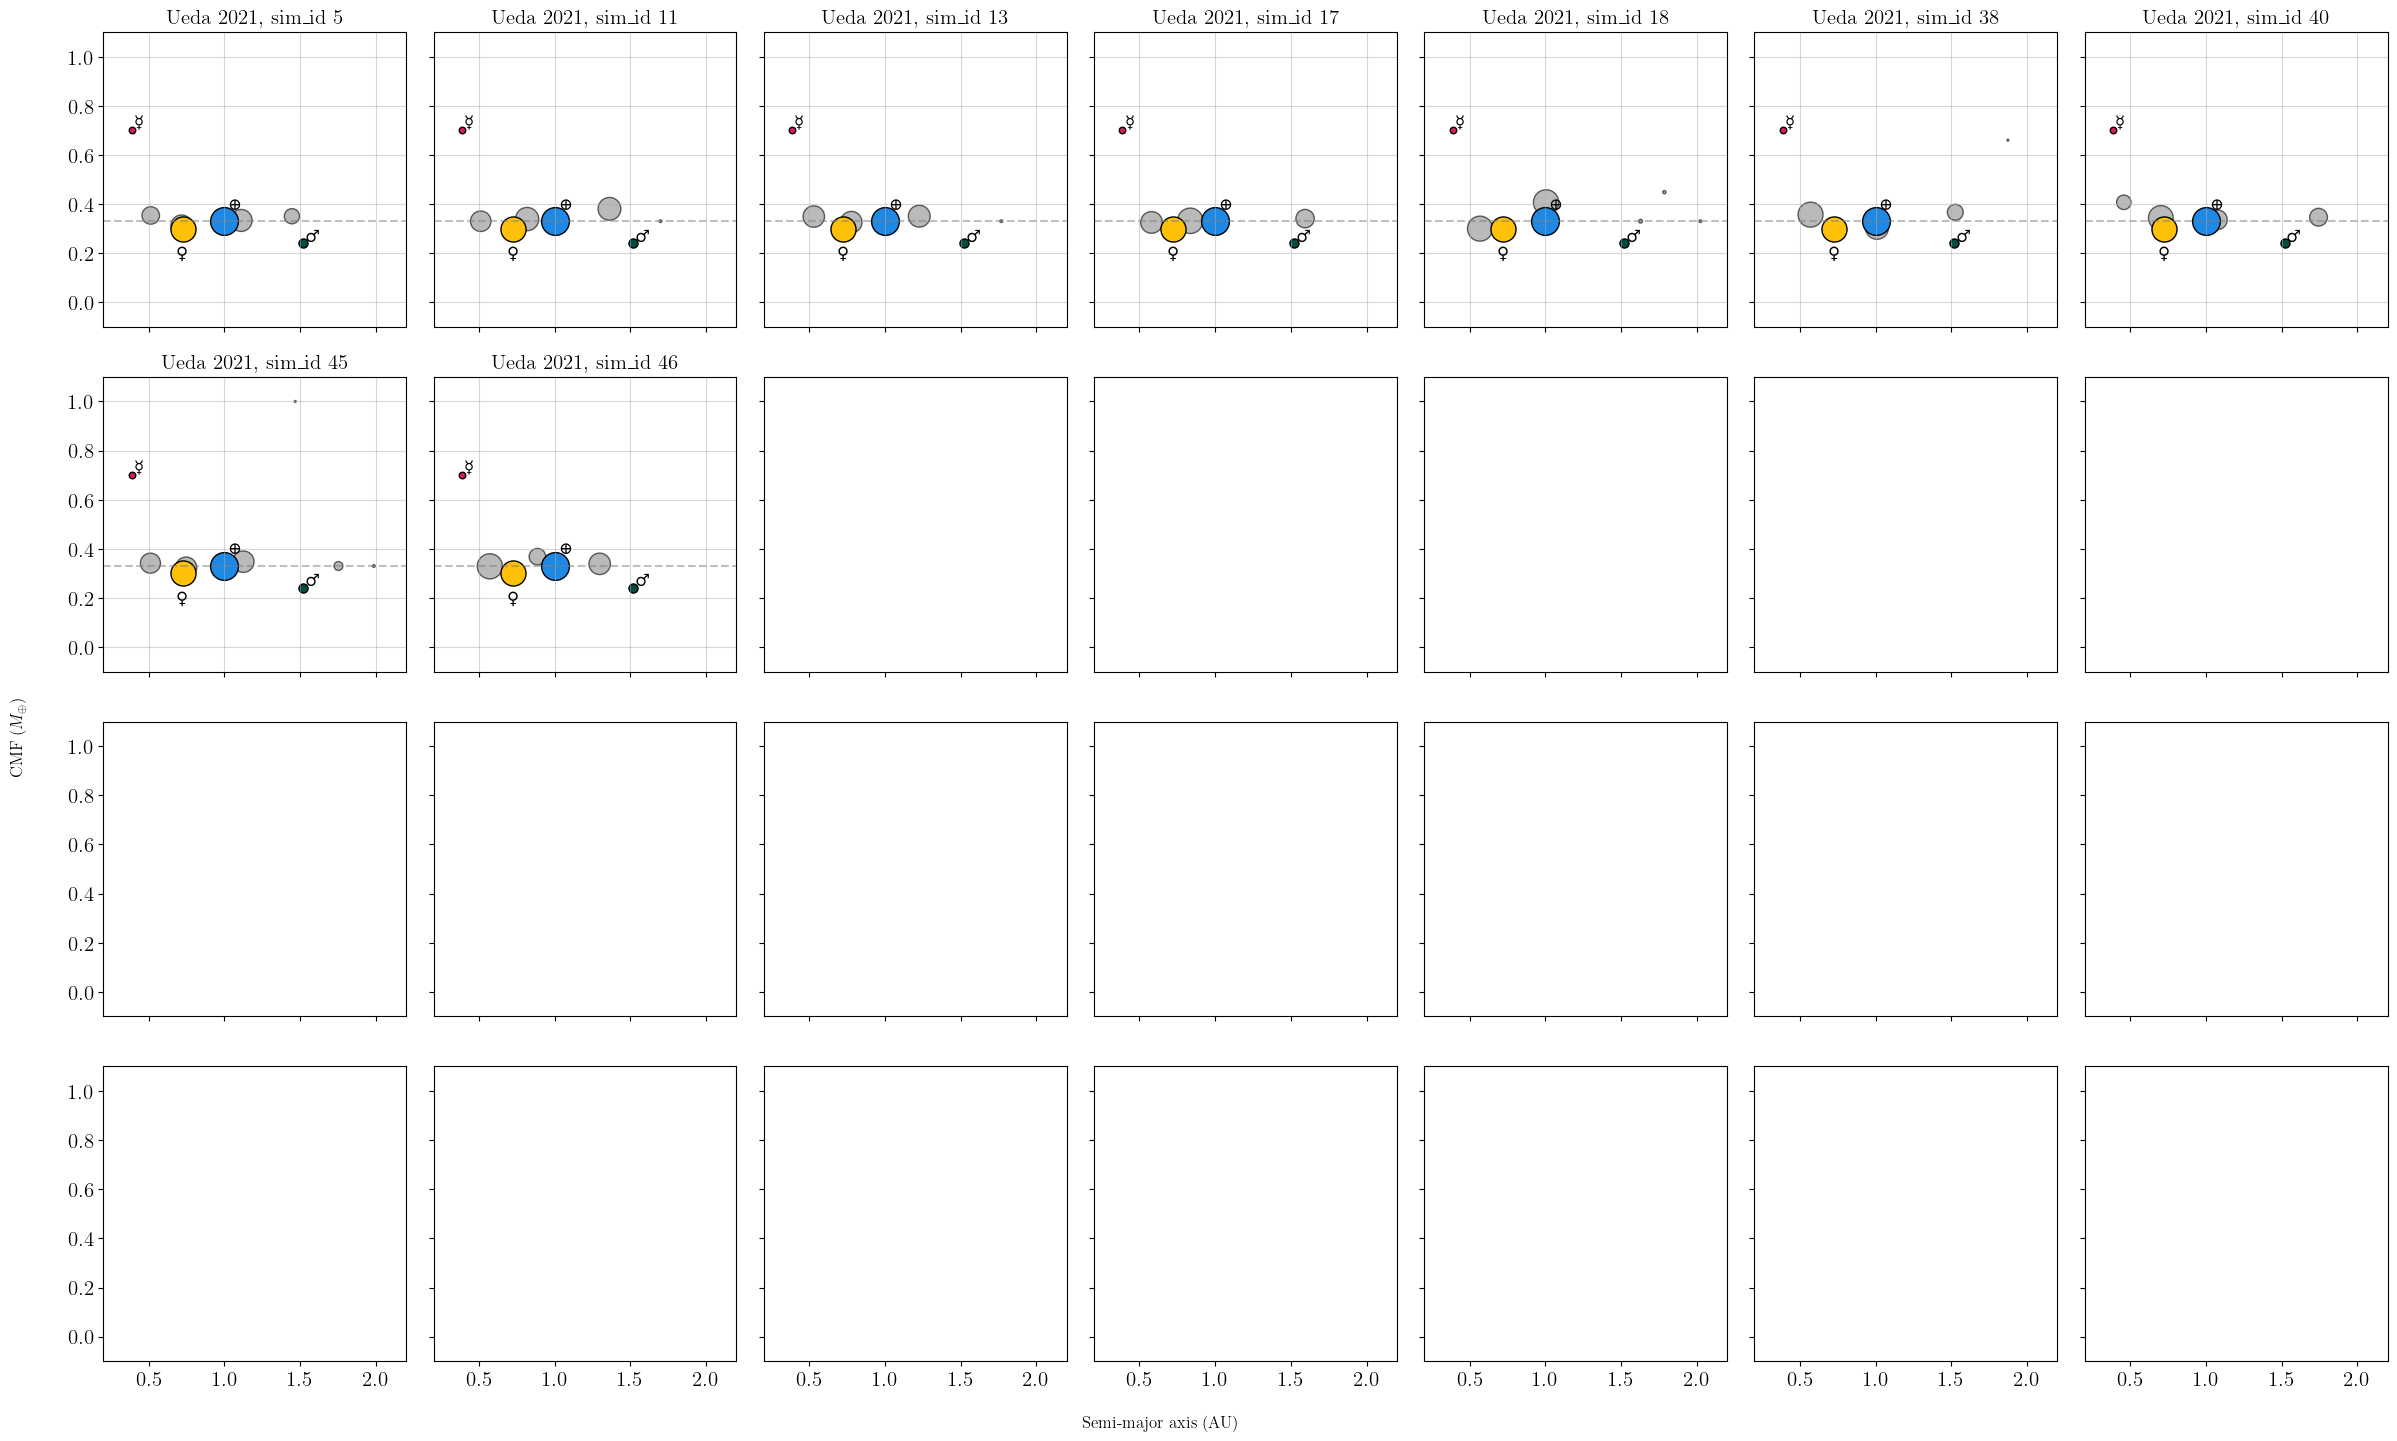

time = 3.00e+08 yrs


In [11]:
cham_bi_tajer_pldf = pd.concat(cham_bi_tajer_pldf_list)

fig, axes = plt.subplots(4, 7, figsize=(25, 15), sharey=True, sharex=True)

# Plot configs
datasets = [
    (f"Ueda 2021, sim_id {sid}", 
     cham_bi_tajer_pldf[cham_bi_tajer_pldf['sim_id'] == sid], 
     colors[3])  # cycles through colors
    for i, sid in enumerate(cham_bi_tajer_pldf['sim_id'].unique())
]

dot_scale = 400

for ax, (label, df, color) in zip(axes.flat, datasets):
    ax.grid(True, alpha = 0.5)
    ax.plot([0.2, 2.2], [0.33, 0.33], linestyle='dashed', color='grey', alpha=0.5)

    ax.scatter(df['semi'], df['cmf'], alpha=0.6, color=color,
               edgecolors='black', linewidths=1, s = df['mass'] * sol_to_earth * dot_scale)

    # Add Mercury & Earth
    ax.scatter(0.387, 0.7, color='#D81B60', edgecolors='black', linewidths=1, s= 0.055 * dot_scale, label = 'Mercury')
    ax.annotate('☿', [0.4, 0.71], fontsize=12, usetex=False)

    ax.scatter(0.723, 0.3, color='#FFC107', edgecolors='black', linewidths=1, s=0.815 * dot_scale, label = 'Venus')
    ax.annotate('♀', [0.68, 0.18], fontsize=12, usetex=False)

    ax.scatter(1, 0.33, color='#1E88E5', edgecolors='black', linewidths=1, s=dot_scale, label = 'Earth')
    ax.annotate('⊕', [1.02, 0.38], fontsize=12, usetex=False)

    ax.scatter(1.52, 0.24, color='#004D40', edgecolors='black', linewidths=1, s=0.107 * dot_scale, label = 'Mars')
    ax.annotate('♂', [1.53, 0.25], fontsize=12, usetex=False)

   
    # Reference lines
    #ax.plot([0.35, 2], [0.3, 0.3], linestyle='dashed', color='grey', alpha=0.5)
    #ax.plot([0.35, 0.35], [0.01, 1.2], linestyle='dashed', color='grey', alpha=0.5)
    #ax.plot([0.7, 0.7], [0.01, 1.2], linestyle='dashed', color='grey', alpha=0.5)

    ax.set_xlim(0.2, 2.2)
    ax.set_ylim(-0.1,1.1)
    ax.set_title(label)

#ax.legend(loc = 'upper right')

# Shared axis labels
fig.text(0.5, 0.04, 'Semi-major axis (AU)', ha='center', fontsize=12)
fig.text(0.04, 0.5, r'CMF ($M_\oplus$)', va='center', rotation='vertical', fontsize=12)

#fig.suptitle('Uniform CMF distributions (0.33)')
plt.tight_layout(rect=[0.05, 0.05, 1, 1])

plt.savefig("all_sims.pdf", dpi=300)  # or .png

plt.show()

print(f"time = {cut_time:.2e} yrs")
#print("mean max time reached for Ueda v1 = ", np.average(maxtimes_ueda_v1)/1e6, "Myrs")
#print("mean max time reached for Cham = ", np.average(maxtimes_cham_bench)/1e6, "Myrs")

Simulation 9 seems pretty cool. Let's find the hash of the high CMF object whose mass is most close to Mercury.

In [12]:
sim_40 = cham_bi_tajer_pldf[cham_bi_tajer_pldf['sim_id'] == 40]
sim_40['mass'] = sim_40['mass'] * sol_to_earth

/var/folders/g0/fl404sj151l2v9xcdkjz9fq80000gn/T/ipykernel_72407/3373885767.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sim_40['mass'] = sim_40['mass'] * sol_to_earth


In [13]:
sim_40

,hash,mass,cmf,tot_disk_cmf,boundary,percentage,semi,sim_id
0,2.000e+00,7.919e-01,3.432e-01,3.000e-01,none,none,7.032e-01,40
1,6.000e+00,2.733e-01,4.070e-01,3.000e-01,none,none,4.588e-01,40
2,1.100e+01,4.102e-01,3.462e-01,3.000e-01,none,none,1.745e+00,40
3,1.300e+01,4.973e-01,3.357e-01,3.000e-01,none,none,1.077e+00,40
4,1.130e+09,4.789e-03,0.000e+00,3.000e-01,none,none,5.203e+00,40


Object 56 seems cool because its mass is 0.04 M_Earth and its CMF is 0.63. Let's follow that one.

In [16]:
sim_40_oi = sim_40[sim_40['hash'] ==  6.000000e+00]

We load simarchive to follow her history. 

In [30]:
sim_40_simarchive = rebound.Simulationarchive("../../../data/cham_bi_tajer/cham_bi_tajer_40/cham_simarchive_40")
sim_40_dataframe = pd.DataFrame(columns=['t', 'm', 'a', 'e'])

for i in range(int(len(sim_40_simarchive))):
    instance = sim_40_simarchive[i]
    sim_40_dataframe.loc[i, 't'] = instance.t
    
    for particle in instance.particles:
        if particle.hash.value == int(sim_40_oi['hash']):
            sim_40_dataframe.loc[i, 'm'] = particle.m
            sim_40_dataframe.loc[i, 'a'] = particle.a
            sim_40_dataframe.loc[i, 'e'] = particle.e
            break  # stop once found

sim_40_dataframe['m'] = sim_40_dataframe['m'] * sol_to_earth

/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:103: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed. Binary file was saved with REBOUND Version 4.4.7. You are currently using REBOUND Version 4.4.8.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: You have to reset function pointers after creating a reb_simulation struct with a binary file.
  warnings.warn(message, RuntimeWarning)
/var/folders/g0/fl404sj151l2v9xcdkjz9fq80000gn/T/ipykernel_72407/2255971668.py:9: FutureWarning: Calling int on a s

In [20]:
len(sim_40_simarchive)

3001

In [22]:
coll_hist_array = np.loadtxt('../../../data/cham_bi_tajer/cham_bi_tajer_40/collision_report.txt',  usecols=(0, 1, 2, 3, 4, 5, 6, 7) )
coll_hist = pd.DataFrame(coll_hist_array, columns=['t', 'type', 'b', 'hash_t', 'm_t', 'r_t', 'hash_p', 'r_p'])

In [26]:
coll_hist_oi = coll_hist[coll_hist['hash_t'] == 6]

In [27]:
coll_hist_oi

,t,type,b,hash_t,m_t,r_t,hash_p,r_p
8,2.805e+04,1.000e+00,3.063e-05,6.000e+00,3.080e-07,2.442e-05,5.400e+01,1.098e-05
13,1.123e+05,1.000e+00,1.470e-05,6.000e+00,3.360e-07,2.514e-05,5.600e+01,1.098e-05
20,2.076e+05,1.000e+00,2.195e-05,6.000e+00,3.640e-07,2.582e-05,5.100e+01,1.098e-05
25,3.186e+05,0.000e+00,2.782e-05,6.000e+00,3.640e-07,2.582e-05,6.600e+01,1.098e-05
34,6.345e+05,2.000e+00,8.154e-06,6.000e+00,3.740e-07,2.605e-05,6.200e+01,1.098e-05
104,7.889e+06,0.000e+00,2.660e-05,6.000e+00,3.740e-07,2.605e-05,2.000e+01,1.098e-05
115,8.757e+06,1.000e+00,9.130e-06,6.000e+00,4.020e-07,2.669e-05,7.400e+01,1.098e-05
119,9.250e+06,1.000e+00,1.420e-05,6.000e+00,4.174e-07,2.702e-05,2.173e+09,8.991e-06
127,1.068e+07,1.000e+00,2.215e-05,6.000e+00,4.458e-07,2.762e-05,2.001e+09,1.104e-05
134,1.158e+07,1.000e+00,9.114e-06,6.000e+00,4.598e-07,2.791e-05,7.800e+01,8.715e-06


Red lines show erosive collisions. Blue lines show mergers, and grey lines show elastic bounce.

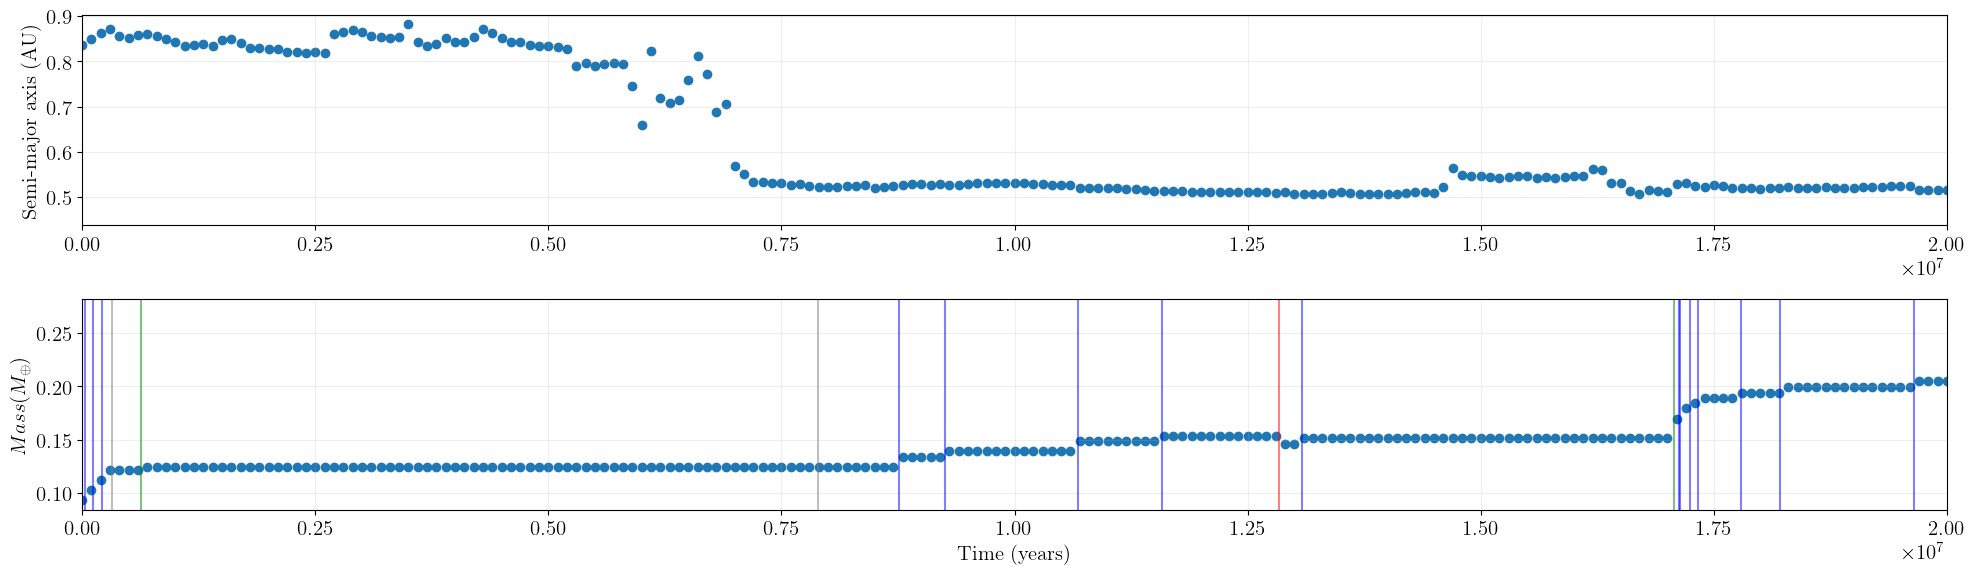

In [28]:
plt.figure(figsize=(20,6))

plt.subplot(2,1,1)
plt.scatter(sim_40_dataframe['t'], sim_40_dataframe['a'])
plt.grid('True', alpha = 0.2)
plt.ylabel('Semi-major axis (AU)')
plt.xlim(0,20e6)

plt.subplot(2,1,2)
for t, type in zip(coll_hist_oi['t'], coll_hist_oi['type']):
    if (type == 3) | (type == 4):
        color = 'red'
    if type == 1:
        color = 'blue'
    if type == 0:
        color = 'gray'
    if type == 2:
        color = 'green'
    plt.axvline(t, color = color, alpha = 0.5)

plt.scatter(sim_40_dataframe['t'], sim_40_dataframe['m'])
plt.grid('True', alpha = 0.2)
plt.ylabel(r'$Mass (M_{\oplus})$')
plt.xlabel('Time (years)')
plt.xlim(0,20e6)

plt.tight_layout()
plt.show()

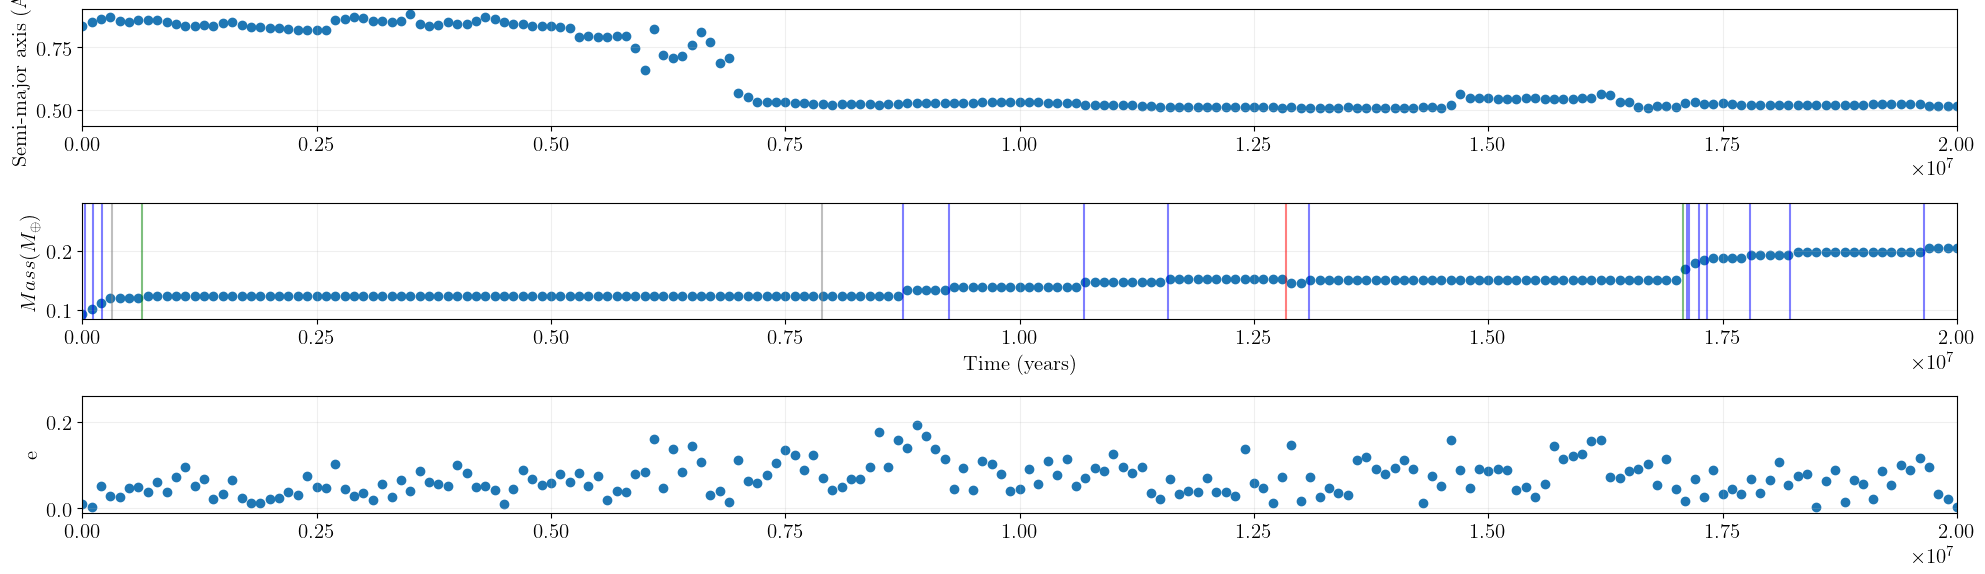

In [31]:
plt.figure(figsize=(20,6))

plt.subplot(3,1,1)
plt.scatter(sim_40_dataframe['t'], sim_40_dataframe['a'])
plt.grid('True', alpha = 0.2)
plt.ylabel('Semi-major axis (AU)')
plt.xlim(0,20e6)

plt.subplot(3,1,2)
for t, type in zip(coll_hist_oi['t'], coll_hist_oi['type']):
    if (type == 3) | (type == 4):
        color = 'red'
    if type == 1:
        color = 'blue'
    if type == 0:
        color = 'gray'
    if type == 2:
        color = 'green'
    plt.axvline(t, color = color, alpha = 0.5)

plt.scatter(sim_40_dataframe['t'], sim_40_dataframe['m'])
plt.grid('True', alpha = 0.2)
plt.ylabel(r'$Mass (M_{\oplus})$')
plt.xlabel('Time (years)')
plt.xlim(0,20e6)

plt.subplot(3,1,3)
plt.scatter(sim_40_dataframe['t'], sim_40_dataframe['e'])
plt.grid('True', alpha = 0.2)
plt.ylabel('e')
plt.xlim(0,20e6)

plt.tight_layout()
plt.show()